# 19th vs Jev, Kumo Tabular and the tree models

Compare **sleep onset within 30 and 60 minutes** on the same 4,390 chronological validation rows. This notebook uses saved remote predictions only: **no API calls, uploads or Kumo inference** on Run All. It refits the three small tree baselines locally with their existing defaults.

Ranking, probability accuracy and useful alert thresholds are different questions. We examine all three, plus uncertainty, performance by baby and agreement between horizons.

The 19th models use `standard` training effort and the `fast` variant. They were trained on 20,091 rows and 52 input features from the September 23 snapshot. No validation labels were uploaded for fitting. No tuning or recalibration is performed here. Older notebooks already examined `test`; we do not treat it as a pristine final benchmark.

In [1]:
from pathlib import Path
import hashlib, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.calibration import calibration_curve
from sklearn.metrics import precision_recall_curve
from baby_ml import Comparison, Predictions, FeatureSpec, JevModel, JevSpec, metrics_table, bootstrap_by_day
from baby_ml.evaluation import MODEL_COLORS, plot_performance
from baby_ml.settings import ML_DIR

RUN = ML_DIR / "data" / "19th" / "sleep-v1"
OUT = RUN / "analysis"
OUT.mkdir(exist_ok=True)
manifest = json.loads((RUN / "manifest.json").read_text())
assert hashlib.sha256((RUN / "snapshot.parquet").read_bytes()).hexdigest() == manifest["frozen_sha256"]
source = ML_DIR / "data" / Path(manifest["source"]).name
assert hashlib.sha256(source.read_bytes()).hexdigest() == manifest["source_sha256"], "Source changed"
df = pd.read_parquet(RUN / "snapshot.parquet")
original = pd.read_parquet(source)
# Kumo's cached context must match the training rows used here.
pd.testing.assert_frame_equal(df.reset_index(drop=True), original.reset_index(drop=True))
LABELS = ["is_asleep_30_mins", "is_asleep_60_mins"]
rows = df.loc[df.split_forward_time == "val"].reset_index(drop=True)
assert FeatureSpec().feature_columns(df) == manifest["input_columns"]
HEADLINE = ["19th", "xgboost", "jev_minimal", "kumo_small"]
COLORS = {"19th": "#007f86", "xgboost": "#eb6834", "jev_minimal": "#4a3aa7", "kumo_small": "#e34948"}
MODEL_COLORS["19th"] = COLORS["19th"]
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
def finish(fig, name):
    fig.savefig(OUT / f"{name}.png", dpi=160, bbox_inches="tight")
    plt.show()
    plt.close(fig)

display(df.groupby("split_forward_time")[LABELS].agg(["size", "mean"]).round(3))

C:\Users\nikil\dbt-baby-data\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


is_asleep_30_mins        is_asleep_60_mins       
                                size   mean              size   mean
split_forward_time                                                  
test                            4232  0.203              4232  0.395
train                          20091  0.331             20091  0.602
val                             4390  0.222              4390  0.426

## Align every prediction by ID

19th, all four Jev layouts, Kumo small (one ensemble member, train-only context), LightGBM, XGBoost and random forest. Missing caches fail explicitly instead of triggering paid or expensive work. Labels and row IDs are checked before comparisons.

Kumo's cache key binds the historical snapshot name and model specification. Jev's legacy cache binds question/layout versions and row IDs, but not a feature-content hash; its provenance is weaker. We reuse the same frozen source as the earlier comparisons, and make no new Jev calls. Jev sees a text rendering rather than exactly the tabular inputs.

In [2]:
comparison = Comparison.run(df, split="val", params={
    "xgboost": {"n_jobs": 4}, "lightgbm": {"n_jobs": 4}, "random_forest": {"n_jobs": 4}})

def aligned(cache, column, label, name):
    assert not cache.prediction_id.duplicated().any(), f"Duplicate IDs: {name}"
    selected = cache.set_index("prediction_id").reindex(rows.prediction_id)
    assert selected[column].notna().all(), f"Missing predictions: {name}"
    p = selected[column].to_numpy(dtype=float)
    assert np.isfinite(p).all() and ((p >= 0) & (p <= 1)).all()
    if "y_true" in selected:
        np.testing.assert_array_equal(selected.y_true, rows[label])
    return Predictions(name=name, label=label, split="val", y_true=rows[label].to_numpy(), p=p)

extra = []
for label in LABELS:
    extra.append(aligned(pd.read_parquet(RUN / label / "val-predictions.parquet"), "p", label, "19th"))
for layout in ["narrative", "numeric", "minimal", "qualitative"]:
    model = JevModel(spec=JevSpec(layout=layout))
    cache = model.cached()  # Local reads only.
    for label in LABELS:
        extra.append(aligned(cache, label, label, model.name))

# Mirror KumoSpec's versioned cache contract without importing torch/sdm.
kumo_spec = dict(size="small", num_estimators=1, seed=0,
                 split_column="split_forward_time", context_splits=["train"],
                 include_baby_name=False, weights_revision="v1.0.0")
for label in LABELS:
    payload = dict(kumo_spec, snapshot=source.name, label=label, split="val")
    cache_key = hashlib.sha256(json.dumps(payload, sort_keys=True).encode()).hexdigest()[:12]
    cache = pd.read_parquet(ML_DIR / "data" / "kumo" / f"{cache_key}.parquet")
    extra.append(aligned(cache, "p", label, "kumo_small"))
comparison = comparison.with_predictions(extra)
metrics = comparison.metrics()
metrics.to_csv(OUT / "all-model-metrics.csv")
display(metrics.round(4))
# Save aligned scores for repeatable analysis without fitting again.
for label in LABELS:
    scores = rows[["prediction_id", label]].copy()
    for pred in comparison.predictions_for(label):
        scores[pred.name] = pred.p
    scores.to_parquet(OUT / f"{label}-scores.parquet", index=False)

def headline(label):
    return [comparison.predictions[(label, name)] for name in HEADLINE]

split  rows  base_rate  pr_auc  roc_auc  \
label             model                                                     
is_asleep_30_mins lightgbm          val  4390     0.2223  0.5666   0.8500   
                  xgboost           val  4390     0.2223  0.5823   0.8529   
                  random_forest     val  4390     0.2223  0.5204   0.8377   
                  19th              val  4390     0.2223  0.6289   0.8540   
                  jev_narrative     val  4390     0.2223  0.5346   0.8114   
                  jev_numeric       val  4390     0.2223  0.4635   0.7387   
                  jev_minimal       val  4390     0.2223  0.5410   0.8207   
                  jev_qualitative   val  4390     0.2223  0.4697   0.8037   
                  kumo_small        val  4390     0.2223  0.5374   0.8235   
is_asleep_60_mins lightgbm          val  4390     0.4260  0.7741   0.8652   
                  xgboost           val  4390     0.4260  0.7735   0.8654   
                  random_forest     val  4390     0.4260  0.7607   0.8589   
                  19th              val  4390     0.4260  0.7580   0.8338   
                  jev_narrative     val  4390     0.4260  0.7763   0.8387   
                  jev_numeric       val  4390     0.4260  0.6834   0.7192   
                  jev_minimal       val  4390     0.4260  0.7826   0.8486   
                  jev_qualitative   val  4390     0.4260  0.7576   0.8372   
                  kumo_small        val  4390     0.4260  0.7176   0.8183   

                                    brier  brier_base_rate  mean_predicted  
label             model                                                     
is_asleep_30_mins lightgbm         0.1384           0.1729          0.3109  
                  xgboost          0.1360           0.1729          0.3011  
                  random_forest    0.1390           0.1729          0.3099  
                  19th             0.1834           0.1729          0.4096  
                  jev_narrative    0.1482           0.1729          0.3419  
                  jev_numeric      0.1850           0.1729          0.3952  
                  jev_minimal      0.1461           0.1729          0.3402  
                  jev_qualitative  0.1662           0.1729          0.3793  
                  kumo_small       0.2589           0.1729          0.5600  
is_asleep_60_mins lightgbm         0.1616           0.2445          0.5451  
                  xgboost          0.1629           0.2445          0.5480  
                  random_forest    0.1646           0.2445          0.5344  
                  19th             0.2163           0.2445          0.6131  
                  jev_narrative    0.1803           0.2445          0.4907  
                  jev_numeric      0.2323           0.2445          0.5131  
                  jev_minimal      0.1706           0.2445          0.4832  
                  jev_qualitative  0.1889           0.2445          0.4976  
                  kumo_small       0.2388           0.2445          0.6754

## Ranking: which awake moments are most likely to precede sleep?

PR-AUC here means **average precision** (the existing project metric), not trapezoidal interpolation. Higher is better. Read it alongside the observed positive rate. Cumulative recall answers: if we flag the highest-scoring 10% of awake moments, what fraction of positive moments do we capture? These are overlapping 10-minute prediction rows, not independent sleep episodes or notification counts.

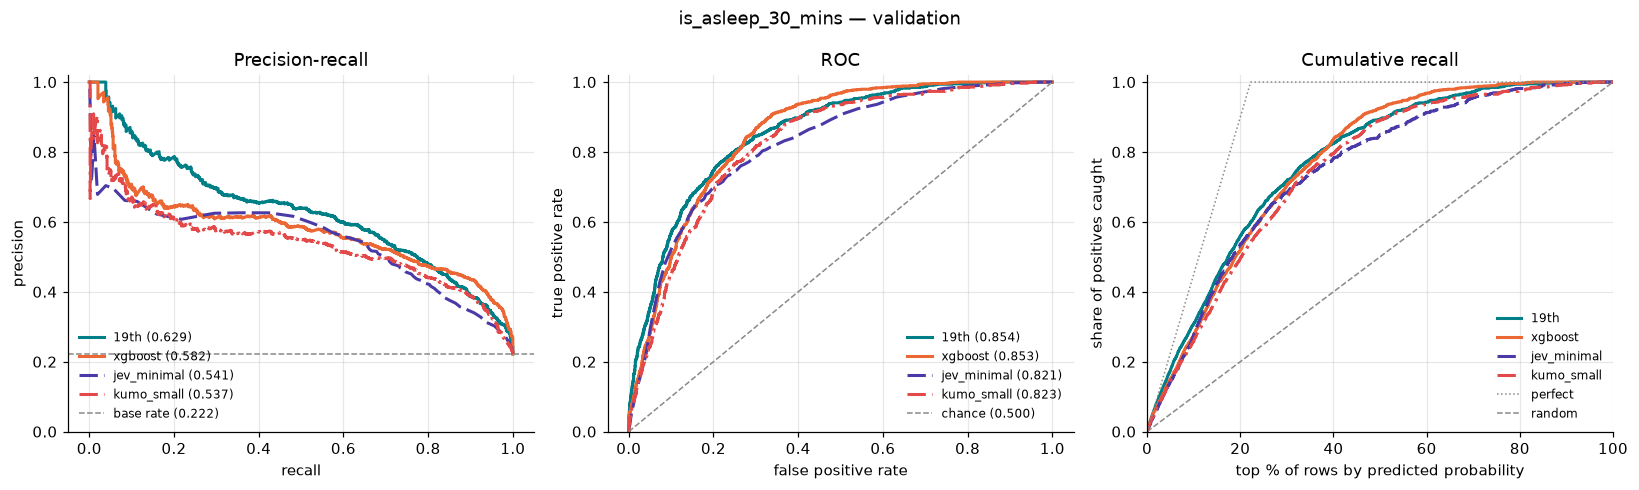

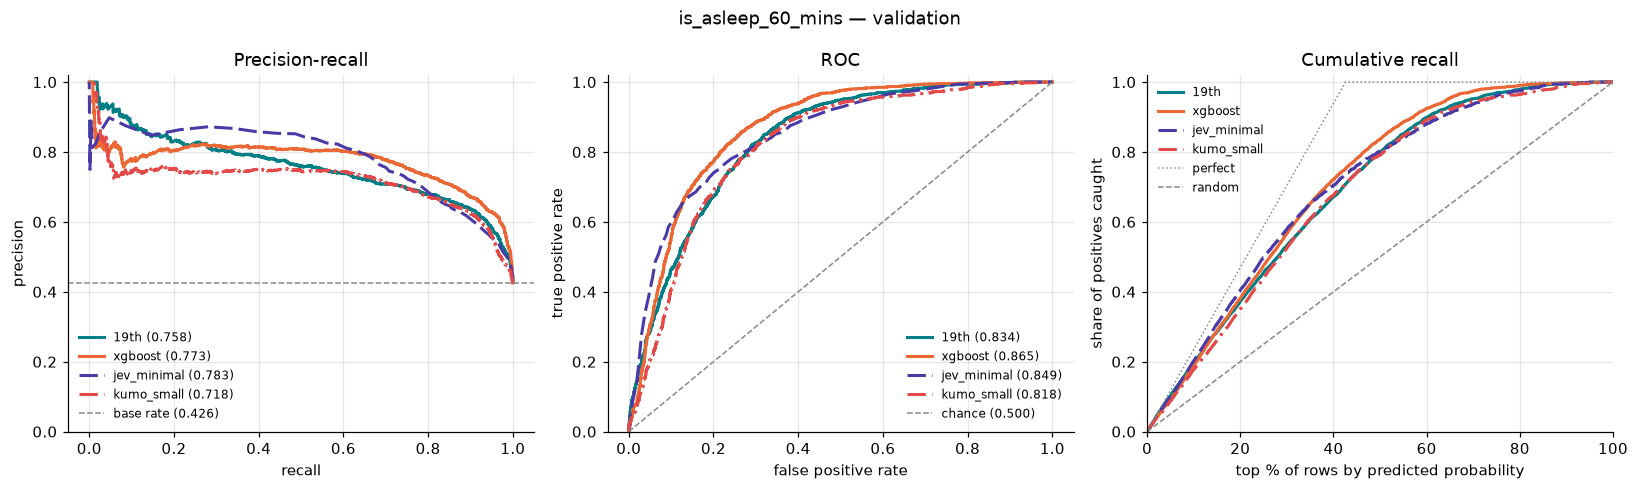

top 5%  top 10%  top 20%  top 30%  top 50%
label             model                                                      
is_asleep_30_mins lightgbm          0.137    0.275    0.519    0.703    0.921
                  xgboost           0.151    0.278    0.519    0.704    0.925
                  random_forest     0.124    0.263    0.488    0.671    0.912
                  19th              0.175    0.308    0.560    0.716    0.893
                  jev_narrative     0.139    0.282    0.532    0.685    0.840
                  jev_numeric       0.133    0.263    0.467    0.618    0.767
                  jev_minimal       0.142    0.277    0.537    0.683    0.849
                  jev_qualitative   0.116    0.251    0.448    0.638    0.856
                  kumo_small        0.144    0.258    0.495    0.667    0.890
is_asleep_60_mins lightgbm          0.094    0.189    0.379    0.567    0.836
                  xgboost           0.090    0.189    0.381    0.566    0.837
                  random_forest     0.088    0.193    0.387    0.560    0.828
                  19th              0.103    0.195    0.372    0.533    0.797
                  jev_narrative     0.099    0.204    0.404    0.584    0.798
                  jev_numeric       0.104    0.199    0.370    0.512    0.697
                  jev_minimal       0.099    0.202    0.404    0.580    0.803
                  jev_qualitative   0.098    0.201    0.379    0.551    0.821
                  kumo_small        0.088    0.178    0.351    0.525    0.791

In [3]:
for label in LABELS:
    finish(plot_performance(headline(label), title=f"{label} — validation"), f"{label}-ranking")
display(comparison.recall_at_percentiles().round(3))

## Calibration: does 70% mean roughly seven in ten?

A curve below the diagonal means overprediction. Quantile bins have approximately equal row counts. The histogram reveals where each model places its scores. Brier measures squared probability error (lower is better); it reflects both calibration and discrimination. The validation-base-rate baseline uses held-out prevalence as a diagnostic reference, not a deployable forecast.

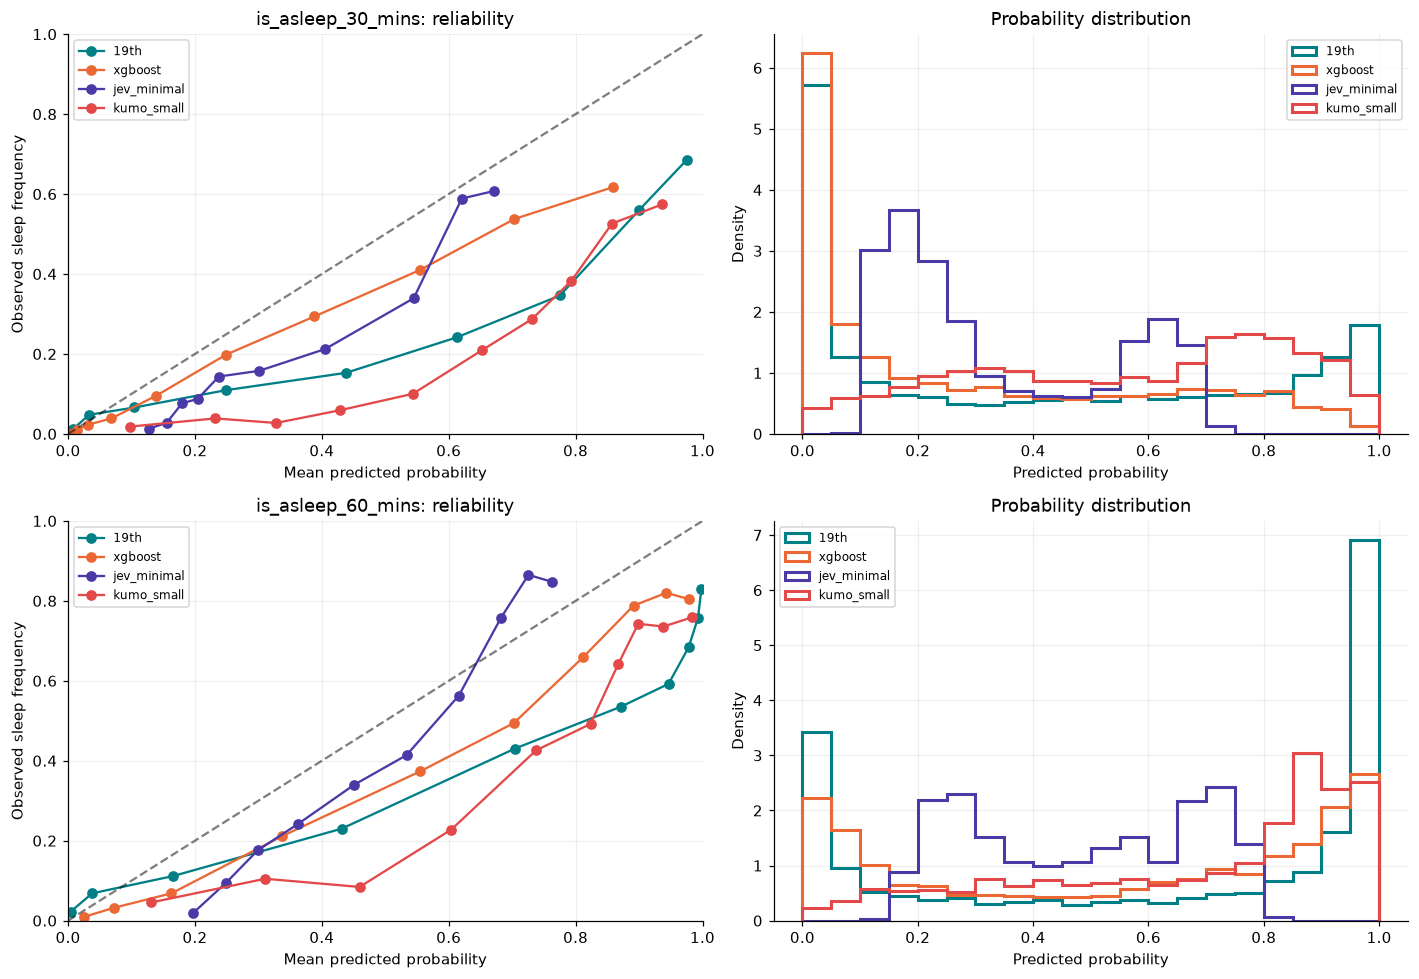

,,base_rate,mean_predicted,brier,brier_base_rate,overprediction_pp
label,model,,,,,
is_asleep_30_mins,19th,0.2223,0.4096,0.1834,0.1729,18.7248
is_asleep_60_mins,19th,0.4260,0.6131,0.2163,0.2445,18.7096
is_asleep_30_mins,xgboost,0.2223,0.3011,0.1360,0.1729,7.8777
is_asleep_60_mins,xgboost,0.4260,0.5480,0.1629,0.2445,12.1993
is_asleep_30_mins,jev_minimal,0.2223,0.3402,0.1461,0.1729,11.7904
is_asleep_60_mins,jev_minimal,0.4260,0.4832,0.1706,0.2445,5.7267
is_asleep_30_mins,kumo_small,0.2223,0.5600,0.2589,0.1729,33.7660
is_asleep_60_mins,kumo_small,0.4260,0.6754,0.2388,0.2445,24.9424


In [4]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for i, label in enumerate(LABELS):
    for pred in headline(label):
        observed, predicted = calibration_curve(pred.y_true, pred.p, n_bins=10, strategy="quantile")
        axes[i, 0].plot(predicted, observed, "o-", label=pred.name, color=COLORS[pred.name])
        axes[i, 1].hist(pred.p, bins=np.linspace(0, 1, 21), histtype="step", linewidth=2,
                        density=True, label=pred.name, color=COLORS[pred.name])
    axes[i, 0].plot([0,1], [0,1], "k--", alpha=.5)
    axes[i, 0].set(title=f"{label}: reliability", xlabel="Mean predicted probability",
                   ylabel="Observed sleep frequency", xlim=(0,1), ylim=(0,1))
    axes[i, 1].set(title="Probability distribution", xlabel="Predicted probability", ylabel="Density")
    for ax in axes[i]: ax.legend(fontsize=8); ax.grid(alpha=.2)
fig.tight_layout()
finish(fig, "calibration")
summary = metrics.loc[(slice(None), HEADLINE), ["base_rate", "mean_predicted", "brier", "brier_base_rate"]].copy()
summary["overprediction_pp"] = 100 * (summary.mean_predicted - summary.base_rate)
display(summary.round(4))

## How uncertain are the differences?

Resample whole **baby-days**, paired across models, rather than pretending adjacent prediction rows are independent. The 500 bootstrap draws are seeded. Gaps are model minus XGBoost: positive is better for PR-AUC/ROC-AUC, negative is better for Brier. Intervals do not cover uncertainty from retraining or dependencies between successive days, and are exploratory rather than a correction for all comparisons.

value  ci_low  ci_high  \
label             metric  model                                  
is_asleep_30_mins brier   19th         0.1834  0.1722   0.1949   
                          jev_minimal  0.1461  0.1401   0.1520   
                          kumo_small   0.2589  0.2434   0.2749   
                          xgboost      0.1360  0.1284   0.1441   
                  pr_auc  19th         0.6289  0.5896   0.6651   
                          jev_minimal  0.5410  0.5048   0.5787   
                          kumo_small   0.5374  0.4864   0.5866   
                          xgboost      0.5823  0.5451   0.6246   
                  roc_auc 19th         0.8540  0.8356   0.8710   
                          jev_minimal  0.8207  0.8045   0.8375   
                          kumo_small   0.8235  0.8054   0.8408   
                          xgboost      0.8529  0.8384   0.8671   
is_asleep_60_mins brier   19th         0.2163  0.1995   0.2355   
                          jev_minimal  0.1706  0.1649   0.1768   
                          kumo_small   0.2388  0.2203   0.2575   
                          xgboost      0.1629  0.1504   0.1746   
                  pr_auc  19th         0.7580  0.7264   0.7901   
                          jev_minimal  0.7826  0.7522   0.8098   
                          kumo_small   0.7176  0.6785   0.7612   
                          xgboost      0.7735  0.7385   0.8105   
                  roc_auc 19th         0.8338  0.8167   0.8514   
                          jev_minimal  0.8486  0.8304   0.8648   
                          kumo_small   0.8183  0.7989   0.8386   
                          xgboost      0.8654  0.8504   0.8824   

                                       gap_vs_xgboost  gap_ci_low  gap_ci_high  
label             metric  model                                                 
is_asleep_30_mins brier   19th                 0.0474      0.0381       0.0581  
                          jev_minimal          0.0102      0.0014       0.0187  
                          kumo_small           0.1229      0.1086       0.1388  
                          xgboost              0.0000      0.0000       0.0000  
                  pr_auc  19th                 0.0466      0.0111       0.0788  
                          jev_minimal         -0.0413     -0.0886       0.0087  
                          kumo_small          -0.0448     -0.0844      -0.0069  
                          xgboost              0.0000      0.0000       0.0000  
                  roc_auc 19th                 0.0011     -0.0129       0.0133  
                          jev_minimal         -0.0321     -0.0507      -0.0145  
                          kumo_small          -0.0294     -0.0442      -0.0146  
                          xgboost              0.0000      0.0000       0.0000  
is_asleep_60_mins brier   19th                 0.0535      0.0433       0.0650  
                          jev_minimal          0.0077     -0.0051       0.0206  
                          kumo_small           0.0760      0.0629       0.0903  
                          xgboost              0.0000      0.0000       0.0000  
                  pr_auc  19th                -0.0154     -0.0439       0.0113  
                          jev_minimal          0.0091     -0.0324       0.0512  
                          kumo_small          -0.0559     -0.0895      -0.0224  
                          xgboost              0.0000      0.0000       0.0000  
                  roc_auc 19th                -0.0316     -0.0433      -0.0189  
                          jev_minimal         -0.0168     -0.0362       0.0038  
                          kumo_small          -0.0470     -0.0634      -0.0305  
                          xgboost              0.0000      0.0000       0.0000

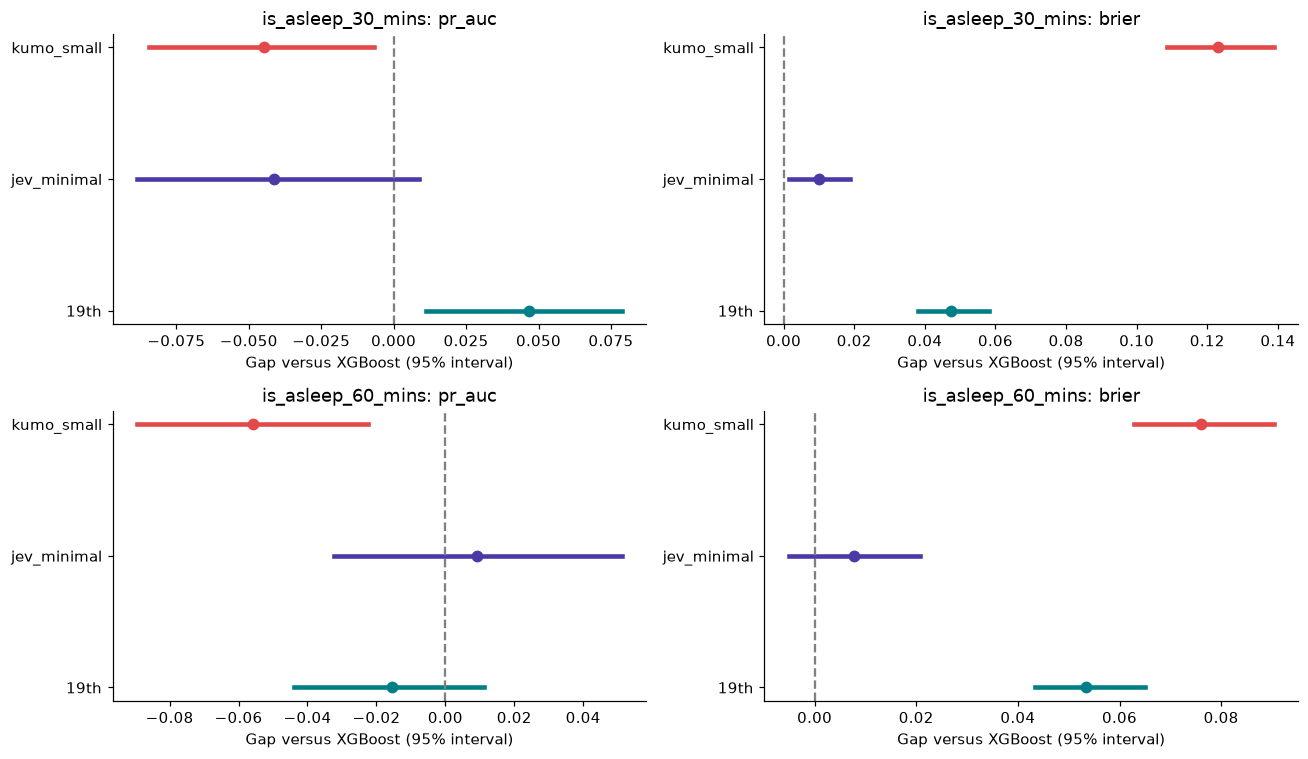

In [5]:
days = (rows.baby_id.astype(str) + "|" + pd.to_datetime(rows.calendar_date).dt.strftime("%Y-%m-%d")).to_numpy()
ci = bootstrap_by_day([p for label in LABELS for p in headline(label)], days,
                      reference="xgboost", n_boot=500, seed=42)
ci.to_csv(OUT / "bootstrap-by-day.csv")
display(ci.round(4))
fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for i, label in enumerate(LABELS):
    for j, metric in enumerate(["pr_auc", "brier"]):
        ax = axes[i,j]
        for k, name in enumerate(["19th", "jev_minimal", "kumo_small"]):
            r = ci.loc[(label, metric, name)]
            ax.plot([r.gap_ci_low, r.gap_ci_high], [k,k], color=COLORS[name], lw=3)
            ax.scatter(r.gap_vs_xgboost, k, color=COLORS[name], s=45)
        ax.axvline(0, color="gray", ls="--")
        ax.set(yticks=range(3), yticklabels=["19th", "jev_minimal", "kumo_small"],
               title=f"{label}: {metric}", xlabel="Gap versus XGBoost (95% interval)")
fig.tight_layout()
finish(fig, "bootstrap-gaps")

## By baby and by age

Aggregate performance can hide which baby benefits. The age plot shows the shift between training and validation; it is a plausible contributor to overprediction, not proof of its cause. Historical features, model fit and calibration can also contribute.

,,,split,rows,base_rate,pr_auc,roc_auc,brier,brier_base_rate,mean_predicted
baby,label,model,,,,,,,,
Ember,is_asleep_30_mins,19th,val,2599,0.193,0.599,0.866,0.190,0.156,0.403
Imogen,is_asleep_30_mins,19th,val,1791,0.265,0.707,0.843,0.174,0.195,0.419
Ember,is_asleep_30_mins,xgboost,val,2599,0.193,0.514,0.851,0.137,0.156,0.296
Imogen,is_asleep_30_mins,xgboost,val,1791,0.265,0.676,0.859,0.134,0.195,0.308
Ember,is_asleep_30_mins,jev_minimal,val,2599,0.193,0.497,0.839,0.134,0.156,0.317
Imogen,is_asleep_30_mins,jev_minimal,val,1791,0.265,0.574,0.786,0.163,0.195,0.374
Ember,is_asleep_30_mins,kumo_small,val,2599,0.193,0.494,0.838,0.276,0.156,0.571
Imogen,is_asleep_30_mins,kumo_small,val,1791,0.265,0.590,0.817,0.234,0.195,0.544
Ember,is_asleep_60_mins,19th,val,2599,0.382,0.746,0.845,0.239,0.236,0.613


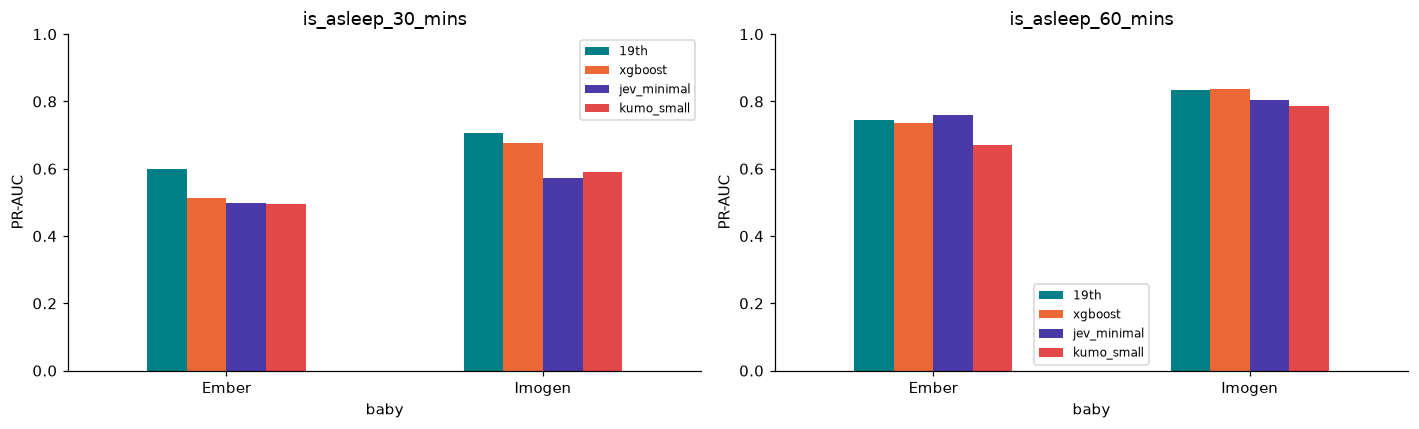

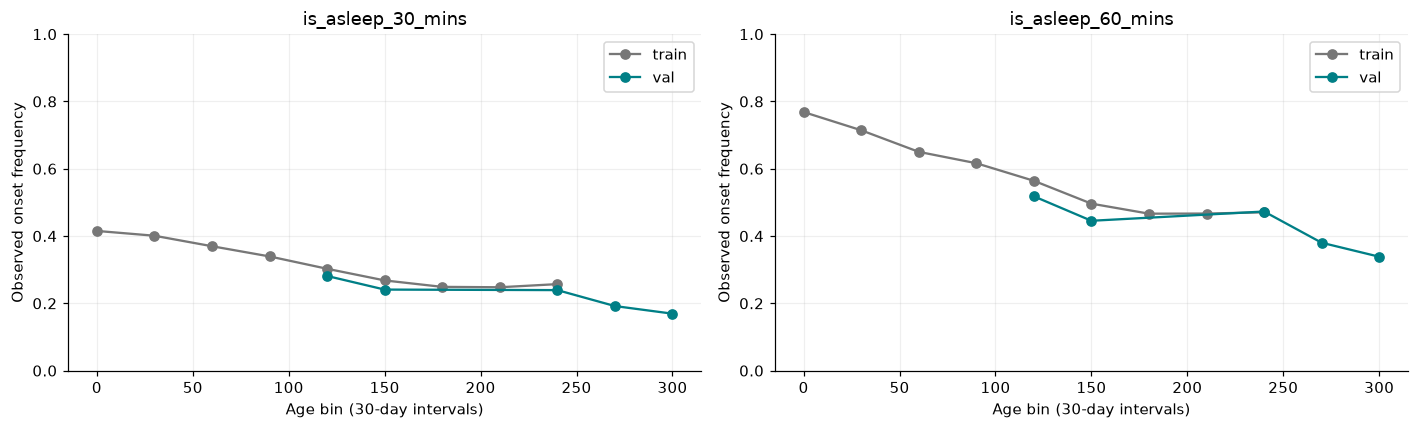

In [6]:
records = []
for label in LABELS:
    for pred in headline(label):
        for baby in rows.baby_name.unique():
            mask = (rows.baby_name == baby).to_numpy()
            sub = pred.model_copy(update={"y_true": pred.y_true[mask], "p": pred.p[mask]})
            record = metrics_table([sub]).reset_index().iloc[0].to_dict()
            record["baby"] = str(baby)
            records.append(record)
by_baby = pd.DataFrame(records)
by_baby.to_csv(OUT / "by-baby.csv", index=False)
display(by_baby.set_index(["baby","label","model"]).round(3))
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, label in zip(axes, LABELS):
    by_baby[by_baby.label == label].pivot(index="baby", columns="model", values="pr_auc")[HEADLINE].plot.bar(
        ax=ax, color=[COLORS[n] for n in HEADLINE], rot=0)
    ax.set(title=label, ylabel="PR-AUC", ylim=(0,1)); ax.legend(fontsize=8)
fig.tight_layout(); finish(fig, "by-baby")
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, label in zip(axes, LABELS):
    for split, color in [("train", "#777777"), ("val", "#007f86")]:
        sub = df[df.split_forward_time == split].copy()
        sub["age_bin"] = (sub.age_days // 30) * 30
        agg = sub.groupby("age_bin")[label].agg(["mean", "size"])
        ax.plot(agg.index, agg["mean"], "o-", label=split, color=color)
    ax.set(title=label, xlabel="Age bin (30-day intervals)", ylabel="Observed onset frequency", ylim=(0,1))
    ax.legend(); ax.grid(alpha=.2)
fig.tight_layout(); finish(fig, "age-shift")

## Alert tradeoffs and consistency between horizons

Thresholds below are diagnostic, not recommendations. A false-positive rate per awake row is not a daily false-alert count; a live alert policy also needs cooldowns and episode-based evaluation. Precision/recall tradeoffs should be chosen with the intended user experience.

For the same awake moment, P(sleep within 30 minutes) must be no larger than P(sleep within 60 minutes). Separately trained heads are not guaranteed to obey this constraint. We show the raw outputs without silently adjusting them.

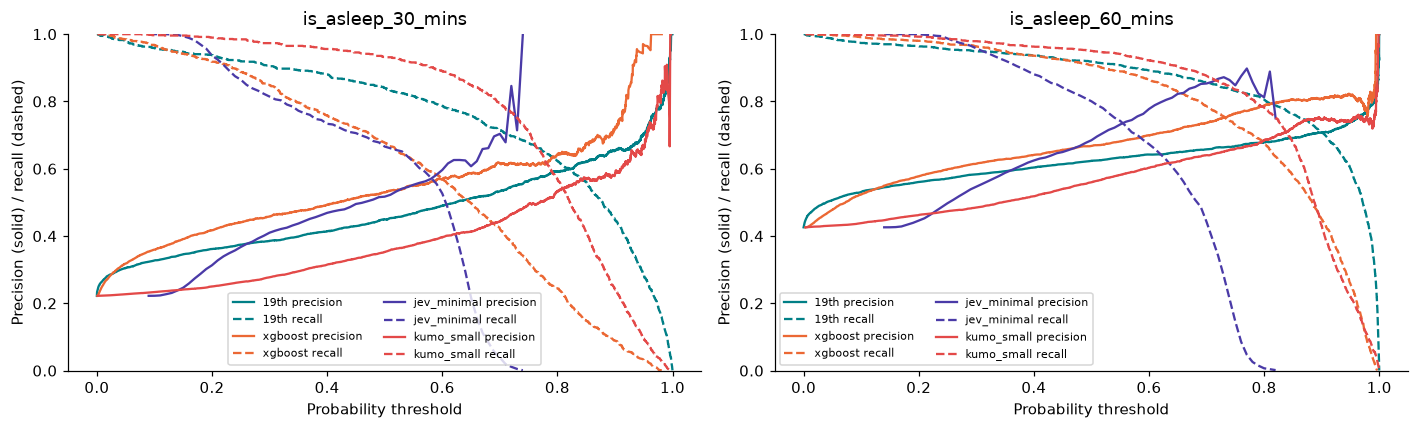

,label,model,threshold,flagged_fraction,precision,recall,false_positive_fraction
1,is_asleep_30_mins,19th,0.5,0.415,0.449,0.839,0.229
4,is_asleep_30_mins,xgboost,0.5,0.284,0.530,0.677,0.133
7,is_asleep_30_mins,jev_minimal,0.5,0.286,0.517,0.666,0.138
10,is_asleep_30_mins,kumo_small,0.5,0.587,0.353,0.932,0.380
13,is_asleep_60_mins,19th,0.5,0.627,0.623,0.918,0.236
16,is_asleep_60_mins,xgboost,0.5,0.579,0.668,0.907,0.192
19,is_asleep_60_mins,jev_minimal,0.5,0.498,0.685,0.801,0.157
22,is_asleep_60_mins,kumo_small,0.5,0.723,0.560,0.950,0.318


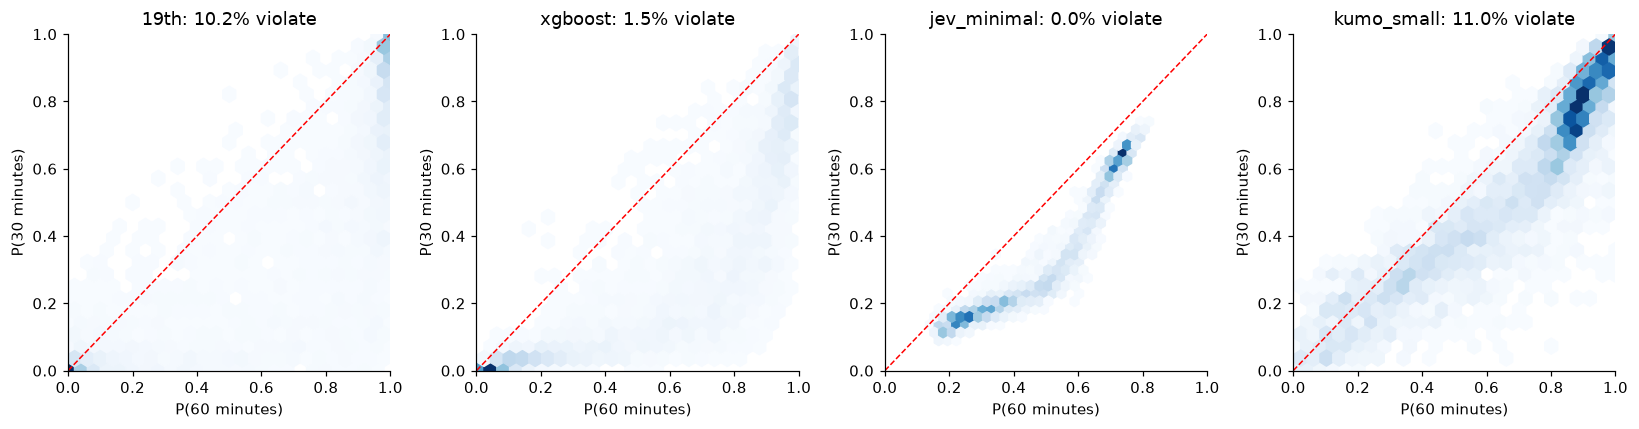

,model,violation_fraction,mean_excess
0,19th,0.1018,0.0047
1,xgboost,0.0146,0.0008
2,jev_minimal,0.0005,0.0000
3,kumo_small,0.1105,0.0060


In [7]:
threshold_records = []
fig, axes = plt.subplots(1, 2, figsize=(13,4))
for ax, label in zip(axes, LABELS):
    for pred in headline(label):
        precision, recall, threshold = precision_recall_curve(pred.y_true, pred.p)
        ax.plot(threshold, precision[:-1], color=COLORS[pred.name], label=f"{pred.name} precision")
        ax.plot(threshold, recall[:-1], color=COLORS[pred.name], ls="--", label=f"{pred.name} recall")
        for t in [0.3, 0.5, 0.7]:
            hit = pred.p >= t
            tp = (hit & (pred.y_true == 1)).sum()
            threshold_records.append(dict(label=label, model=pred.name, threshold=t,
                flagged_fraction=hit.mean(), precision=tp/hit.sum() if hit.any() else np.nan,
                recall=tp/pred.y_true.sum(), false_positive_fraction=((hit) & (pred.y_true == 0)).mean()))
    ax.set(title=label, xlabel="Probability threshold", ylabel="Precision (solid) / recall (dashed)", ylim=(0,1))
    ax.legend(fontsize=7, ncol=2)
fig.tight_layout(); finish(fig, "thresholds")
thresholds = pd.DataFrame(threshold_records)
thresholds.to_csv(OUT / "thresholds.csv", index=False)
display(thresholds[thresholds.threshold == .5].round(3))
fig, axes = plt.subplots(1,4,figsize=(15,4))
consistency = []
for ax, name in zip(axes, HEADLINE):
    p30, p60 = [comparison.predictions[(label,name)].p for label in LABELS]
    violation = p30 > p60
    consistency.append(dict(model=name, violation_fraction=violation.mean(), mean_excess=np.maximum(p30-p60,0).mean()))
    ax.hexbin(p60,p30,gridsize=25,mincnt=1,cmap="Blues")
    ax.plot([0,1],[0,1],"r--",lw=1)
    ax.set(title=f"{name}: {violation.mean():.1%} violate",xlabel="P(60 minutes)",ylabel="P(30 minutes)",xlim=(0,1),ylim=(0,1))
fig.tight_layout(); finish(fig, "horizon-consistency")
display(pd.DataFrame(consistency).round(4))

## What actually trained, and why was it fast?

Our pipeline was:

**Laptop: assemble a labeled CSV → 19th servers: fit each model → laptop: save the model → hosted API: validation inference.**

Each upload was about 4.7 MB: 20,091 rows × 52 features plus one binary label. The dbt pipeline had already transformed raw logs into useful signals such as time since waking, recent sleep totals, age, feeds and time of day. The model only had to learn a focused mapping from those features to a probability. We did not ask it to learn language or generate text. Existing labels also avoided 19th's optional labeling step.

[19th's product description](https://www.19th.com/) says it searches model architectures, sizes and training strategies, then distills strong candidates into smaller deployment models. **That is a vendor-level description, not a trace of these particular runs.** The fit responses do not reveal the selected architecture, parameter count, candidate count, hardware, objective, internal split or per-stage timing. We cannot establish that our standard run searched hundreds of models, or that it fine-tuned a particular foundation model. We also did not instrument training durations; polling showed both ready quickly, but that is not a hardware benchmark.

The [Training API docs](https://19th.com/docs/training) distinguish training effort (`standard` here) from the downloadable model variant (`fast` here). Both downloaded files are 1,061,888 bytes, approximately 1.01 MiB. Small deployment size helps explain why local prediction is practical; it does **not** tell us the compute cost of training or prove a particular internal algorithm.

### Can we fine-tune it on the laptop?

**We did not locally fine-tune 19th.** The documented workflow trains through the API and downloads a model for local **inference** with a compatible SDK. The docs reviewed do not establish a supported local 19th fine-tuning API. The notebook can run offline because it reads cached scores and trains only the small tree baselines; it does not run the downloaded `.tfpb` files. No 19th runtime has been installed or tested here.

| Model | What our examples do | Where this experiment runs | What changes |
|---|---|---|---|
| 19th | Labeled examples submitted for task training | Training and validation inference on 19th servers | Task-specific model is produced; exact internals undisclosed |
| XGBoost / LightGBM / random forest | Supervised fitting on train rows | Laptop CPU | Tree splits and leaf predictions |
| Kumo small | Train rows become labeled context for new queries | Earlier local CPU run; cache read here | No weight updates in our workflow |
| Jev | Text description and yes/no questions, without our labels | Earlier hosted calls; cache read here | No task-specific training in our workflow |

[NVIDIA's Kumo model card](https://huggingface.co/nvidia/Kumo-Tabular) demonstrates context/query prediction. That is why Kumo can adapt to our table without a fine-tuning loop. The [19th overview](https://19th.com/docs) explicitly separates API training from local or hosted prediction. The [Jev introduction](https://docs.typesafe.ai/introduction) describes typed questions and structured answers.

Ordinary supervised tabular learning is feasible on this laptop because the dataset is modest and the output is narrow. Local fine-tuning of neural models is a different workload: feasibility depends on parameter count, precision, optimizer state, batch size and hardware. A downloaded 1 MB inference artifact alone does not establish that its training procedure is available or cheap locally.

## Reading the result and deciding what to do next

19th's 30-minute ranking is promising, but its raw probability scale overpredicts. At 60 minutes XGBoost ranks better in this run. Compare the paired intervals above before describing a gap as convincing; also check Imogen's subgroup rather than relying only on pooled performance.

The train-to-validation positive-rate drop is one plausible contributor to inflated scores, and both age and daily routine change with time. This notebook does not establish a causal explanation or automatically fix calibration. A sensible next experiment is a time-ordered calibration slice, followed by evaluation on a later period not already examined in previous notebooks. Compare a calibrated existing model with a refit using recent training data; enforce or model the relationship between horizons explicitly if probabilities are shown to users.

The training cohort filters long tracking gaps and requires later observed sleep. Validation metrics therefore apply to that observed cohort, not automatically to every live app situation. No new test evaluation, remote training or production changes are performed by this notebook.